In [26]:
''' 
# This should be all nessesary installs for the notebook to run

!pip install torch
!pip install numpy
!pip install plotly
!pip install scipy
!pip install tqdm
!pip install matplotlib
!pip install --upgrade nbconvert
'''

' \n# This should be all nessesary installs for the notebook to run\n\n!pip install torch\n!pip install numpy\n!pip install plotly\n!pip install scipy\n!pip install tqdm\n!pip install matplotlib\n!pip install --upgrade nbconvert\n'

In [27]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import numpy as np
import plotly.figure_factory as ff
import plotly.graph_objects as go
from plotly.express.colors import sequential
from scipy.stats import qmc
from torch.optim.lr_scheduler import StepLR
from tqdm import tqdm
import matplotlib.pyplot as plt
print(f"Using device: {device}")

file_path = rf'C:\Users\marcs\Downloads\Hooke_hole-coupled-4-2.csv' #N1=4, N2=2, R=0.10
#file_path = rf'C:\Users\marcs\Downloads\Hooke_hole-coupled-30-15.csv' #N1=30, N2=15, R=0.10

Using device: cuda


# PINN for a hyperelastic elastic square plate

In [28]:
# Applied outer stresses
N1 = 4
N2 = 2
# Quadratic plate length
L = 1.0
# Lame constants
MU = 10
LBD = 20
# The code allows the freedom to make this an ellipse. for a circle with R=10: Rx and Ry should both be 0.10
Rx = 0.1 # Rx1
Ry = 0.1 # Ry2
# Scaling factor
X = 2
# Edge samples
N = 50 * X
# Number of collocation points
M = 500 * X**2
# Epochs
EPOCHS = 200000
# Learning rate
LR = 0.001
# Gain parameter for initialization
GAIN = 0.5
# Scheduler step width
STEP = 5000
# Gamma factor of scheduler
GAMMA = 0.975
# Number of hidden neurons
HN = 50
# Number of hidden layers
LAYERS = 5
# Fourier features
FEATURES = 100
# Weight of PDE loss
W_PDE = 1.0
# Weight of Dirichlet loss
W_DIR = 1.0
# Weight of Neumann loss
W_NEU = 1.0
# Weight of hole loss
W_HOLE = 1.0
# Weight update factor
ALPHA = 0.9
# Variance
SIGMA = 1.0
# precision
DTYPE = torch.float32

print(f"Number of boundary points each: {N}")
print(f"Number of collocation points: {M}")
print(f"Total number of points: {5*N + M}")

Number of boundary points each: 100
Number of collocation points: 2000
Total number of points: 2500


In [29]:
# Sample either all points or only collocation points

def sample_domain(): # All points
    # Create collocation points
    points = qmc.LatinHypercube(d=2).random(M)
    mask = (((points[:, 0] ** 2) / (Rx**2)) + ((points[:, 1] ** 2) / (Ry**2))) > 1
    collocation = torch.tensor(points[mask], dtype=DTYPE, device=device)

    # Top boundary
    x_top = L * torch.tensor(qmc.LatinHypercube(d=1).random(N), dtype=DTYPE, device=device)
    y_top = L * torch.ones((N, 1), dtype=DTYPE, device=device)
    top = torch.column_stack([x_top, y_top])

    # Right boundary
    x_right = L * torch.ones((N, 1), dtype=DTYPE, device=device)
    y_right = L * torch.tensor(qmc.LatinHypercube(d=1).random(N), dtype=DTYPE, device=device)
    right = torch.column_stack([x_right, y_right])

    # Bottom boundary
    NN = int(N * (L - Rx) / L)
    rand_samp = qmc.LatinHypercube(d=1).random(NN)
    x_bottom = Rx + (L - Rx) * torch.tensor(rand_samp, dtype=DTYPE, device=device)
    y_bottom = torch.zeros((NN, 1), dtype=DTYPE, device=device)
    bottom = torch.column_stack([x_bottom, y_bottom])

    # Left boundary
    NN = int(N * (L - Ry) / L)
    rand_samp = qmc.LatinHypercube(d=1).random(NN)
    x_left = torch.zeros((NN, 1), dtype=DTYPE, device=device)
    y_left = Ry + (L - Ry) * torch.tensor(rand_samp, dtype=DTYPE, device=device)
    left = torch.column_stack([x_left, y_left])

    # Hole boundary
    rand_samp = qmc.LatinHypercube(d=1).random(int(N * np.pi * Rx / L)).ravel()
    phi = 0.5 * np.pi * torch.tensor(rand_samp, dtype=DTYPE, device=device) 
    x_hole = Rx * torch.cos(phi)
    y_hole = Ry * torch.sin(phi)
    n_hole = torch.stack([-Ry * torch.cos(phi), -Rx * torch.sin(phi)]).T
    n_hole = n_hole / torch.linalg.norm(n_hole, axis=1)[:, None]
    hole = torch.column_stack([x_hole, y_hole])

    return collocation, top, bottom, left, right, hole, n_hole


collocation, top, bottom, left, right, hole, n_hole = sample_domain()


def generate_fixed_bc_points(): # Fixed BC points
    # Top boundary
    x_top = L * torch.tensor(qmc.LatinHypercube(d=1).random(N), dtype=DTYPE, device=device)
    y_top = L * torch.ones((N, 1), dtype=DTYPE, device=device)
    top = torch.column_stack([x_top, y_top])

    # Right boundary
    x_right = L * torch.ones((N, 1), dtype=DTYPE, device=device)
    y_right = L * torch.tensor(qmc.LatinHypercube(d=1).random(N), dtype=DTYPE, device=device)
    right = torch.column_stack([x_right, y_right])

    # Bottom boundary
    NN = int(N * (L - Rx) / L)
    rand_samp = qmc.LatinHypercube(d=1).random(NN)
    x_bottom = Rx + (L - Rx) * torch.tensor(rand_samp, dtype=DTYPE, device=device)
    y_bottom = torch.zeros((NN, 1), dtype=DTYPE, device=device)
    bottom = torch.column_stack([x_bottom, y_bottom])

    # Left boundary
    NN = int(N * (L - Ry) / L)
    rand_samp = qmc.LatinHypercube(d=1).random(NN)
    x_left = torch.zeros((NN, 1), dtype=DTYPE, device=device)
    y_left = Ry + (L - Ry) * torch.tensor(rand_samp, dtype=DTYPE, device=device)
    left = torch.column_stack([x_left, y_left])

    # Hole boundary
    rand_samp = qmc.LatinHypercube(d=1).random(int(N * np.pi * Rx / L)).ravel()
    phi = 0.5 * np.pi * torch.tensor(rand_samp, dtype=DTYPE, device=device)
    x_hole = Rx * torch.cos(phi)
    y_hole = Ry * torch.sin(phi)
    n_hole = torch.stack([-Ry * torch.cos(phi), -Rx * torch.sin(phi)]).T
    n_hole = n_hole / torch.linalg.norm(n_hole, axis=1)[:, None]
    hole = torch.column_stack([x_hole, y_hole])

    return top, bottom, left, right, hole, n_hole

# Generate BC points once at the start
fixed_top, fixed_bottom, fixed_left, fixed_right, fixed_hole, fixed_n_hole = generate_fixed_bc_points()

# Modified function that only samples collocation points
def sample_domain2():
    # Create collocation points only
    points = qmc.LatinHypercube(d=2).random(M)
    mask = (((points[:, 0] ** 2) / (Rx**2)) + ((points[:, 1] ** 2) / (Ry**2))) > 1
    collocation = torch.tensor(points[mask], dtype=DTYPE, device=device)
    
    # Return the fixed BC points along with new collocation points
    return collocation, fixed_top, fixed_bottom, fixed_left, fixed_right, fixed_hole, fixed_n_hole

# Now each call will only generate new collocation points
collocation, top, bottom, left, right, hole, n_hole = sample_domain2()

# Visualize geometry
with torch.inference_mode():
    mode = "markers"
    gray = dict(color="#C9C5BC")
    green = dict(color="#006561")
    black = dict(color="black")
    
    # Convert all tensors to CPU numpy arrays
    hole_cpu = hole.cpu().numpy() if hole.is_cuda else hole.numpy()
    n_hole_cpu = n_hole.cpu().numpy() if n_hole.is_cuda else n_hole.numpy()
    collocation_cpu = collocation.cpu().numpy() if collocation.is_cuda else collocation.numpy()
    top_cpu = top.cpu().numpy() if top.is_cuda else top.numpy()
    bottom_cpu = bottom.cpu().numpy() if bottom.is_cuda else bottom.numpy()
    left_cpu = left.cpu().numpy() if left.is_cuda else left.numpy()
    right_cpu = right.cpu().numpy() if right.is_cuda else right.numpy()
    
    fig = ff.create_quiver(
        hole_cpu[:, 0], 
        hole_cpu[:, 1], 
        n_hole_cpu[:, 0], 
        n_hole_cpu[:, 1], 
        marker=black
    )
    
    fig.add_trace(go.Scatter(x=collocation_cpu[:, 0], y=collocation_cpu[:, 1], mode=mode, marker=gray))
    fig.add_trace(go.Scatter(x=top_cpu[:, 0], y=top_cpu[:, 1], mode=mode, marker=black))
    fig.add_trace(go.Scatter(x=bottom_cpu[:, 0], y=bottom_cpu[:, 1], mode=mode, marker=green))
    fig.add_trace(go.Scatter(x=left_cpu[:, 0], y=left_cpu[:, 1], mode=mode, marker=green))
    fig.add_trace(go.Scatter(x=right_cpu[:, 0], y=right_cpu[:, 1], mode=mode, marker=black))
    fig.add_trace(go.Scatter(x=hole_cpu[:, 0], y=hole_cpu[:, 1], mode=mode, marker=black))
    
    fig.layout.yaxis.scaleanchor = "x"
    fig.update_layout(
        template="none",
        width=400,
        height=400,
        margin=dict(l=0, r=0, b=0, t=0),
        showlegend=False,
    )
    fig.update_xaxes(visible=False)
    fig.update_yaxes(visible=False)
    fig.show()


In [30]:
# Initialize net and optimizer and loss metric

class Net(torch.nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        # Input layer
        self.layers = torch.nn.ModuleList(
            [torch.nn.Linear(2 * FEATURES, HN, device=device).type(DTYPE)]
        )
        # Hidden layers
        for _ in range(LAYERS - 1):
            self.layers.append(torch.nn.Linear(HN, HN).type(DTYPE))
        # Output layer
        self.output_layer = torch.nn.Linear(HN, 2, device=device).type(DTYPE)

        # Initialize weights with scaled Xavier/Glorot scheme
        for layer in self.layers:
            torch.nn.init.xavier_uniform_(layer.weight, gain=GAIN)

        # Initialize output layer weights
        torch.nn.init.xavier_uniform_(self.output_layer.weight, gain=GAIN)

        # Sample B from normal distribution
        self.B = torch.normal(0.0, SIGMA, size=(2, FEATURES), dtype=DTYPE, device=device)

    def forward(self, x):  # x input [Batchsize, 2]
        x = torch.cat(
            [torch.sin(2 * np.pi * x @ self.B), torch.cos(2 * np.pi * x @ self.B)],
            dim=-1,
        )
        for layer in self.layers:
            x = torch.tanh(layer(x))
        return self.output_layer(x)

net = Net()
net = net.to(device)
optimizer = torch.optim.Adam(net.parameters(), lr=LR)
scheduler = StepLR(optimizer, step_size=STEP, gamma=GAMMA)
mse = torch.nn.MSELoss()

## Linear

We want to solve linear elasticity on the domain, which means ultimately that we want to minimize the residual of the following PDE
$$\frac{\partial \sigma_{11}}{\partial x_1} + \frac{\partial \sigma_{12}}{\partial x_2} = 0$$
$$\frac{\partial \sigma_{21}}{\partial x_1} + \frac{\partial \sigma_{22}}{\partial x_2} = 0$$
with stress
$$ \sigma_{ij} = 2\mu \varepsilon_{ij} + \frac{2\lambda\mu}{2\mu+\lambda} \varepsilon_{kk} \delta_{ij} $$
and strain
$$ \varepsilon_{ij} = \frac{1}{2} \left( \frac{\partial u_i}{\partial x_j} +  \frac{\partial u_j}{\partial x_i}\right).$$

In [31]:
#Linear
'''
file_path = # insert linear reference file here

def epsilon(x):
    # Compute deformation gradient
    dudx = torch.func.jacrev(net)(x)
    return 0.5 * (dudx + dudx.T + dudx.T @ dudx)

def sigma(x):
    # Compute (small deformation) strain
    eps = epsilon(x)
    # Compute linear elastic strain (assuming plane stress)
    return 2.0 * MU * eps + (2 * LBD * MU) / (2 * MU + LBD) * torch.trace(
        eps
    ) * torch.eye(2)

def pde_residual(x):
    # Compute stress gradient
    dsdx = torch.func.jacrev(sigma)(x)
    # Momentum balance in x direction
    residual_x = dsdx[0, 0, 0] + dsdx[0, 1, 1]
    # Momentum balance in y direction
    residual_y = dsdx[1, 0, 0] + dsdx[1, 1, 1]
    return residual_x, residual_y
'''

'\nfile_path = # insert linear reference file here\n\ndef epsilon(x):\n    # Compute deformation gradient\n    dudx = torch.func.jacrev(net)(x)\n    return 0.5 * (dudx + dudx.T + dudx.T @ dudx)\n\ndef sigma(x):\n    # Compute (small deformation) strain\n    eps = epsilon(x)\n    # Compute linear elastic strain (assuming plane stress)\n    return 2.0 * MU * eps + (2 * LBD * MU) / (2 * MU + LBD) * torch.trace(\n        eps\n    ) * torch.eye(2)\n\ndef pde_residual(x):\n    # Compute stress gradient\n    dsdx = torch.func.jacrev(sigma)(x)\n    # Momentum balance in x direction\n    residual_x = dsdx[0, 0, 0] + dsdx[0, 1, 1]\n    # Momentum balance in y direction\n    residual_y = dsdx[1, 0, 0] + dsdx[1, 1, 1]\n    return residual_x, residual_y\n'

## Neo-Hookean



$\sigma$ the **Cauchy stress tensor**, is defined as:

$$
\sigma = \frac{1}{J} P F^T
$$

with:
- \(F\): The **deformation gradient**:
  $$
  F = I + \nabla u
  $$
- \(J\): The determinant of \(F\):
  $$
  J = \det(F)
  $$
- \(P\): The **First Piola-Kirchhoff stress tensor**:
  $$
  P = \mu F + (\lambda \ln J - \mu) F^{-T}
  $$
- \(S\): The **Second Piola-Kirchhoff stress tensor**:
  $$
  S = P F^{-T}
  $$


We want to minimize the residual of the following PDE:

$$
\frac{\partial P_{11}}{\partial x_1} + \frac{\partial P_{12}}{\partial x_2} = 0
$$
$$
\frac{\partial P_{21}}{\partial x_1} + \frac{\partial P_{22}}{\partial x_2} = 0
$$

For an incompressible material: J = 1


Formeln -----------------------> https://arxiv.org/pdf/2205.14148
und https://arxiv.org/pdf/2104.09623

In [32]:
#Non-linear Neo-Hookean compressible uncoupled with logarithmic strain energy function, force applied with regards to reference configuration

def deformation_gradient(x):
    # Deformation gradient F = I + grad(u)
    dudx = torch.func.jacrev(net)(x)
    return torch.eye(2, dtype=DTYPE, device=device) + dudx

def first_piola_kirchhoff_stress(x):
    # For Neo-Hookean Material P
    F = deformation_gradient(x)
    J = torch.det(F)
    return MU * F + (LBD * torch.log(J) - MU) * torch.inverse(F).T

def sigma(x):
    # Cauchy stress sigma
    F = deformation_gradient(x)
    J = torch.det(F)
    P = first_piola_kirchhoff_stress(x)
    return (1 / J) * P @ F.T

def pde_residual(x):
    # Compute stress gradient
    dsdx = torch.func.jacrev(first_piola_kirchhoff_stress)(x)
    # Momentum balance in x and y directions
    residual_x = dsdx[0, 0, 0] + dsdx[0, 1, 1]
    residual_y = dsdx[1, 0, 0] + dsdx[1, 1, 1]
    return residual_x, residual_y


# not really needed
def second_piola_kirchhoff_stress(x):
    # Second Piola-Kirchhoff stress
    F = deformation_gradient(x)
    P = first_piola_kirchhoff_stress(x)
    return P * torch.inverse(F).T


## Boundary conditions

Left:

$$ u_1 = 0$$
$$ P_{21} = 0 $$

Bottom:

$$ u_2 = 0$$
$$ P_{12} = 0 $$

Top:

$$ P \cdot N = N_2$$

Right:

$$ P \cdot N = N_1$$

Hole:

$$ P \cdot N = 0 $$

In [33]:
def compute_physics_losses(collocation, top, bottom, left, right, hole, n_hole):
    # pde
    all_points = torch.cat([collocation, top, bottom, left, right, hole])
    res_x, res_y = torch.vmap(pde_residual)(all_points)
    zeros = torch.zeros_like(res_x, dtype=DTYPE, device=device)
    pde_error = mse((res_x), zeros) + mse((res_y), zeros)

    # left boundary
    pred_left = net(left)
    bc_left = torch.zeros_like(pred_left[:, 0], dtype=DTYPE, device=device)
    left_error = mse(pred_left[:, 0], bc_left)

    pred_stress_left = torch.vmap(first_piola_kirchhoff_stress)(left)
    pred_s_left_xy = pred_stress_left[:, 1, 0]
    s_left_xy = torch.zeros_like(pred_s_left_xy, dtype=DTYPE, device=device)
    left_symm_error = mse(pred_s_left_xy, s_left_xy)

    # bottom boundary
    pred_bottom = net(bottom)
    bc_bottom = torch.zeros_like(pred_bottom[:, 1], dtype=DTYPE, device=device)
    bottom_error = mse(pred_bottom[:, 1], bc_bottom)

    pred_stress_bottom = torch.vmap(first_piola_kirchhoff_stress)(bottom)
    pred_s_bottom_xy = pred_stress_bottom[:, 0, 1]
    s_bottom_xy = torch.zeros_like(pred_s_bottom_xy, dtype=DTYPE, device=device)
    bottom_symm_error = mse(pred_s_bottom_xy, s_bottom_xy)

    # top boundary
    pred_stress_top = torch.vmap(first_piola_kirchhoff_stress)(top)
    pred_s_top_yy = pred_stress_top[:, 1, 1]
    pred_s_top_xy = pred_stress_top[:, 0, 1]
    s_top_yy = N2 * torch.ones_like(pred_s_top_yy, dtype=DTYPE, device=device)
    s_top_xy = torch.zeros_like(pred_s_top_xy, dtype=DTYPE, device=device)
    top_error = mse(pred_s_top_yy, s_top_yy) + mse(pred_s_top_xy, s_top_xy)

    # right boundary
    pred_stress_right = torch.vmap(first_piola_kirchhoff_stress)(right)
    pred_s_right_xx = pred_stress_right[:, 0, 0]
    pred_s_right_xy = pred_stress_right[:, 1, 0]
    s_right_xx = N1 * torch.ones_like(pred_s_right_xx, dtype=DTYPE, device=device)
    s_right_xy = torch.zeros_like(pred_s_right_xy, dtype=DTYPE, device=device)
    right_error = mse(pred_s_right_xx, s_right_xx) + mse(pred_s_right_xy, s_right_xy)
    # hole boundary
    stress_hole = torch.vmap(first_piola_kirchhoff_stress)(hole)
    traction = torch.einsum("...ij,...j->...i", stress_hole, n_hole)
    zeros = torch.zeros_like(traction[:, 0], dtype=DTYPE, device=device)
    hole_error = mse(traction[:, 0], zeros) + mse(traction[:, 1], zeros)

    return left_error, left_symm_error, right_error, bottom_error, bottom_symm_error, top_error, hole_error, pde_error

In [34]:
def compute_gradient_norm(loss):
    grads = torch.autograd.grad(loss, net.parameters(), allow_unused=True)
    return sum(0 if grad is None else torch.linalg.norm(grad) for grad in grads)

def update_weight(weight, grad_sum, norm):
    new_weight = grad_sum / norm
    return ALPHA * weight + (1 - ALPHA) * new_weight

def reference_data(csv_path):
    data = np.loadtxt(file_path, delimiter=',', skiprows=1)
    points = data[:, 0:2]        # Columns 0 and 1 (x, y)
    stresses = data[:, 2:5]      # Columns 2, 3, and 4 (stress components) sigma_x, sigma_y, sigma_xy
    strains = data[:, 5:8]       # Columns 5, 6, and 7 (strain components) epsilon_x, epsilon_y, epsilon_xy
    displacements = data[:, 8:10] # Columns 8 and 9 (deformation components) u_x, u_y
    first_piola = data[:, 10:13] # Columns 10, 11, and 12 (first Piola-Kirchhoff stress components) P_x, P_y, P_xy
    second_piola = data[:, 13:16] # Columns 13, 14, and 15 (second Piola-Kirchhoff stress components) S_x, S_y, S_xy

    return (
        torch.tensor(points, dtype=DTYPE, device=device),
        torch.tensor(stresses, dtype=DTYPE, device=device),
        torch.tensor(strains, dtype=DTYPE, device=device),
        torch.tensor(displacements, dtype=DTYPE, device=device),
        torch.tensor(first_piola, dtype=DTYPE, device=device),
        torch.tensor(second_piola, dtype=DTYPE, device=device)
    )

ref_points, ref_stresses, ref_strains, ref_displacements, ref_piola1, ref_piola2 = reference_data(file_path)

tol = 0.05 #tolerance

def extract_ellipse_boundary_data(file_path, tol):
    data = np.loadtxt(file_path, delimiter=',', skiprows=1)

    points = data[:, 0:2]  # x, y columns
    x, y = points[:, 0], points[:, 1]

    # Ellipse equation
    mask = np.abs((x**2/Rx**2) + (y**2/Ry**2) - 1) < tol

    return (
        torch.tensor(points[mask], dtype=DTYPE, device=device), # x and y
        torch.tensor(data[mask, 2:5], dtype=DTYPE, device=device)  # stress components sigma_x and sigma_y
    )

points_hole, hole_stress_ref = extract_ellipse_boundary_data(file_path, tol=0.05)

In [35]:
def save_checkpoint(epoch, model, optimizer, scheduler, loss, path):
    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'loss': loss,
        'B_matrix': model.B  # Saves the B matrix
    }, path)

def load_checkpoint(path, model, optimizer, scheduler):
    checkpoint = torch.load(path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    model.B = checkpoint['B_matrix'].to(device)  # Load B matrix to device
    return checkpoint['epoch'], checkpoint['loss']

weight_history = {
    'epoch': [],
    'W_DIR': [],
    'W_NEU': [],
    'W_PDE': [],
    'W_HOLE': []
}

In [36]:
# Load checkpoint

'''
checkpoint = torch.load('best_model.pth', map_location=device)  # Load to CPU/GPU

# Restore states
net.load_state_dict(checkpoint['model_state_dict'])
optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
scheduler.load_state_dict(checkpoint['scheduler_state_dict'])

# Restore the B matrix
if 'B_matrix' in checkpoint:
    net.B = checkpoint['B_matrix'].to(device)

# Get other saved info
epoch = checkpoint['epoch']
loss = checkpoint['loss']
'''

"\ncheckpoint = torch.load('best_model.pth', map_location=device)  # Load to CPU/GPU\n\n# Restore states\nnet.load_state_dict(checkpoint['model_state_dict'])\noptimizer.load_state_dict(checkpoint['optimizer_state_dict'])\nscheduler.load_state_dict(checkpoint['scheduler_state_dict'])\n\n# Restore the B matrix\nif 'B_matrix' in checkpoint:\n    net.B = checkpoint['B_matrix'].to(device)\n\n# Get other saved info\nepoch = checkpoint['epoch']\nloss = checkpoint['loss']\n"

## Training

In [37]:
# setting sample_domain() to sample_domain2() only resamples collocation points

import time
best_loss = float('inf')
best_epoch = -1

def compute_gradient_norm(loss):
    grads = torch.autograd.grad(loss, net.parameters(), allow_unused=True)
    return sum(0 if grad is None else torch.linalg.norm(grad) for grad in grads)

def update_weight(weight, grad_sum, norm):
    new_weight = grad_sum / norm
    return ALPHA * weight + (1 - ALPHA) * new_weight

net.train()
# Create an instance of the tqdm progress bar
progress_bar = tqdm(range(EPOCHS), desc="Training", unit="epoch")

# Record start time
start_time = time.time()
time_limit = 6000000000000000000 # if wanted for benechmarking (limit is in seconds)

# Wrap the epoch loop with tqdm
for epoch in progress_bar:
    # Check if time limit has been exceeded
    elapsed_time = time.time() - start_time
    if elapsed_time > time_limit:
        print(f"\nTraining stopped after {elapsed_time/60:.1f} minutes")
        
        # Perform final evaluation
        net.eval()
        with torch.no_grad():
            # Compute current loss
            collocation, top, bottom, left, right, hole, n_hole = sample_domain()
            (
                left_l,
                left_sl,
                right_l,
                bottom_l,
                bottom_sl,
                top_l,
                hole_l,
                pde_l,
            ) = compute_physics_losses(collocation, top, bottom, left, right, hole, n_hole)
            
            dirichlet_losses = left_l + bottom_l
            neumann_losses = right_l + top_l + left_sl + bottom_sl
            current_loss = (
                W_DIR * dirichlet_losses
                + W_NEU * neumann_losses
                + W_HOLE * hole_l
                + W_PDE * pde_l
            )
            current_loss_weightless = dirichlet_losses + neumann_losses + hole_l + pde_l
            
            # pred stress and displacement
            pred_displacements = net(ref_points)
            pred_stress = torch.vmap(sigma)(ref_points)

            current_lr = optimizer.param_groups[0]['lr']

            with torch.no_grad():
                # Pred stress and displacement
                pred_displacements = net(ref_points)
                pred_stress = torch.vmap(sigma)(ref_points)
                pred_hole_stress = torch.vmap(sigma)(points_hole)
                current_lr = optimizer.param_groups[0]['lr']
                
                # DISPLACEMENT ERRORS
                displacement_error_x_wMAPE = 100 * torch.mean(torch.abs(pred_displacements[:, 0] - ref_displacements[:, 0])) / torch.mean(torch.abs(ref_displacements[:, 0])) 
                displacement_error_y_wMAPE = 100 * torch.mean(torch.abs(pred_displacements[:, 1] - ref_displacements[:, 1])) / torch.mean(torch.abs(ref_displacements[:, 1]))
                
                # Max absolute errors
                max_disp_error_x = torch.max(torch.abs(pred_displacements[:, 0] - ref_displacements[:, 0]))
                max_disp_error_y = torch.max(torch.abs(pred_displacements[:, 1] - ref_displacements[:, 1]))

                # Normalized average stress errors 
                stress_error_xx_wMAPE = 100 * torch.mean(torch.abs(pred_stress[:, 0, 0] - ref_stresses[:, 0]))/ torch.mean(torch.abs(ref_stresses[:, 0]))
                stress_error_yy_wMAPE = 100  * torch.mean(torch.abs(pred_stress[:, 1, 1] - ref_stresses[:, 1]))/ torch.mean(torch.abs(ref_stresses[:, 1]))
                stress_error_xy_wMAPE = 100 * torch.mean(torch.abs(pred_stress[:, 0, 1] - ref_stresses[:, 2]))/ torch.mean(torch.abs(ref_stresses[:, 2]))
                
                # Average percentage errors
                hole_stress_error_xx_wMAPE = 100 * torch.mean(torch.abs(pred_hole_stress[:, 0, 0] - hole_stress_ref[:, 0])) / torch.mean(torch.abs(hole_stress_ref[:, 0]))
                hole_stress_error_yy_wMAPE = 100 * torch.mean(torch.abs(pred_hole_stress[:, 1, 1] - hole_stress_ref[:, 1])) / torch.mean(torch.abs(hole_stress_ref[:, 1]))
                hole_stress_error_xy_wMAPE = 100 * torch.mean(torch.abs(pred_hole_stress[:, 0, 1] - hole_stress_ref[:, 2])) / torch.mean(torch.abs(hole_stress_ref[:, 2]))

                # Max stress error
                max_hole_stress_error_xx_wMAPE = torch.max(torch.abs(pred_hole_stress[:, 0, 0] - hole_stress_ref[:, 0]))
                max_hole_stress_error_yy_wMAPE = torch.max(torch.abs(pred_hole_stress[:, 1, 1] - hole_stress_ref[:, 1]))
                max_hole_stress_error_xy_wMAPE = torch.max(torch.abs(pred_hole_stress[:, 0, 1] - hole_stress_ref[:, 2]))
                
                # Max absolute errors
                max_hole_stress_error_xx = torch.max(torch.abs(pred_hole_stress[:, 0, 0] - hole_stress_ref[:, 0]))
                max_hole_stress_error_yy = torch.max(torch.abs(pred_hole_stress[:, 1, 1] - hole_stress_ref[:, 1]))
                max_hole_stress_error_xy = torch.max(torch.abs(pred_hole_stress[:, 0, 1] - hole_stress_ref[:, 2]))

                print("\n")
                print(f"New best model at epoch {epoch} with loss {best_loss:.4f}")
                print(f"----------------------------------------------------------------------------------------")
                print(f"Displacement wMAPE in x₁: {displacement_error_x_wMAPE.item():.2f}%", f"      Max Displacement Error in x₁: {max_disp_error_x.item():.4f}")
                print(f"Displacement wMAPE in x₂: {displacement_error_y_wMAPE.item():.2f}%", f"      Max Displacement Error in x₂: {max_disp_error_y.item():.4f}")
                print(f"----------------------------------------------------------------------------------------")
                print(f"Stress wMAPE in x₁: {stress_error_xx_wMAPE.item():.2f}%", f"      Max Stress Error in x₁: {max_hole_stress_error_xx.item():.4f}")
                print(f"Stress wMAPE in x₂: {stress_error_yy_wMAPE.item():.2f}%", f"      Max Stress Error in x₂: {max_hole_stress_error_yy.item():.4f}")
                print(f"Stress wMAPE in x₁x₂: {stress_error_xy_wMAPE.item():.2f}%", f"      Max Stress Error in x₁x₂: {max_hole_stress_error_xy.item():.4f}")
                print(f"----------------------------------------------------------------------------------------")
                print(f"Hole wMAPE in x₁: {hole_stress_error_xx_wMAPE.item():.2f}%", f"      Max Hole Stress Error in x₁: {max_hole_stress_error_xx.item():.4f}")
                print(f"Hole wMAPE in x₂: {hole_stress_error_yy_wMAPE.item():.2f}%", f"      Max Hole Stress Error in x₂: {max_hole_stress_error_yy.item():.4f}")
                print(f"Hole wMAPE in x₁x₂: {hole_stress_error_xy_wMAPE.item():.2f}%", f"      Max Hole Stress Error in x₁x₂: {max_hole_stress_error_xy.item():.4f}")
                print(f"----------------------------------------------------------------------------------------")
                print(f"Loss: {loss.item():.6f}", f"  Weightless Loss: {loss_weightless.item():.6f}", f"  LR: {current_lr:.6e}")
                print(f"----------------------------------------------------------------------------------------")
                print(f"Weights: W_DIR={W_DIR:.2e}, W_NEU={W_NEU:.2e}, W_PDE={W_PDE:.2e}, W_HOLE={W_HOLE:.2e}")
                print(f"----------------------------------------------------------------------------------------")
                print("\n")
            
            # Optionally save final model if it's better than best
            if current_loss_weightless < best_loss:
                print(f"Final model is better than previous best - saving...")
                #save_checkpoint(epoch, net, optimizer, scheduler, current_loss, 'best_model.pth') # save the model (1 more below commented out)
            
            net.train()
        break
        
    # Sample domain randomly
    if epoch % 100 == 0:
        collocation, top, bottom, left, right, hole, n_hole = sample_domain2()

    optimizer.zero_grad()

    # Compute physics losses
    (
        left_l,
        left_sl,
        right_l,
        bottom_l,
        bottom_sl,
        top_l,
        hole_l,
        pde_l,
    ) = compute_physics_losses(collocation, top, bottom, left, right, hole, n_hole)

    # Aggregate losses
    dirichlet_losses = left_l + bottom_l
    neumann_losses = right_l + top_l + left_sl + bottom_sl
    loss = (
        W_DIR * dirichlet_losses
        + W_NEU * neumann_losses
        + W_HOLE * hole_l
        + W_PDE * pde_l
    )

    loss.backward(retain_graph=True)
    optimizer.step()
    
    # Rebalance weights every 100 epochs
    if (epoch) % 1000 == 0:
        (
            left_l,
            left_sl,
            right_l,
            bottom_l,
            bottom_sl,
            top_l,
            hole_l,
            pde_l,
        ) = compute_physics_losses(collocation, top, bottom, left, right, hole, n_hole)
        grad_dir = compute_gradient_norm(left_l + bottom_l)
        grad_neu = compute_gradient_norm(right_l + top_l + left_sl + bottom_sl)
        grad_hole = compute_gradient_norm(hole_l)
        grad_pde = compute_gradient_norm(pde_l)
        grad_sum = grad_dir + grad_neu + grad_hole + grad_pde
        W_DIR = update_weight(W_DIR, grad_sum, grad_dir)
        W_NEU = update_weight(W_NEU, grad_sum, grad_neu)
        W_HOLE = update_weight(W_HOLE, grad_sum, grad_hole)
        W_PDE = update_weight(W_PDE, grad_sum, grad_pde)

        weight_history['epoch'].append(epoch)
        weight_history['W_DIR'].append(W_DIR)
        weight_history['W_NEU'].append(W_NEU)
        weight_history['W_PDE'].append(W_PDE)
        weight_history['W_HOLE'].append(W_HOLE)
    
    # Make scheduler step after full epoch
    scheduler.step()
    '''
    with torch.no_grad(): # this could be used to stop training early based on hole stress accuracy in X1 direction
        net.eval
        pred_displacements = net(ref_points)
        pred_hole_stress = torch.vmap(sigma)(points_hole)
        hole_stress_error_xx_wMAPE = 100 * torch.mean(torch.abs(pred_hole_stress[:, 0, 0] - hole_stress_ref[:, 0])) / torch.mean(torch.abs(hole_stress_ref[:, 0]))

        if hole_stress_error_xx_wMAPE .item() <= 0.0:
            print(f"\nTraining stopped as wMAPE in x₁ reached {hole_stress_error_xx_wMAPE .item():.2f}% (3%)")
            break 
        net.train()
    '''
    loss_weightless = dirichlet_losses + neumann_losses + hole_l + pde_l # Calculate weightless loss
    if epoch % 10000 == 0:
        if loss_weightless < best_loss: 
            best_loss = loss_weightless
            best_epoch = epoch
            #save_checkpoint(epoch, net, optimizer, scheduler, loss, 'best_model.pth') # save model 
            net.eval()
            pred_displacements = net(ref_points)
            pred_stress = torch.vmap(sigma)(ref_points)
            pred_hole_stress = torch.vmap(sigma)(points_hole)
            current_lr = optimizer.param_groups[0]['lr']
            
            # DISPLACEMENT ERRORS
            displacement_error_x_wMAPE = 100 * torch.mean(torch.abs(pred_displacements[:, 0] - ref_displacements[:, 0])) / torch.mean(torch.abs(ref_displacements[:, 0])) 
            displacement_error_y_wMAPE = 100 * torch.mean(torch.abs(pred_displacements[:, 1] - ref_displacements[:, 1])) / torch.mean(torch.abs(ref_displacements[:, 1]))
            
            # Max absolute errors
            max_disp_error_x = torch.max(torch.abs(pred_displacements[:, 0] - ref_displacements[:, 0]))
            max_disp_error_y = torch.max(torch.abs(pred_displacements[:, 1] - ref_displacements[:, 1]))

            # Normalized average stress errors 
            stress_error_xx_wMAPE = 100 * torch.mean(torch.abs(pred_stress[:, 0, 0] - ref_stresses[:, 0]))/ torch.mean(torch.abs(ref_stresses[:, 0]))
            stress_error_yy_wMAPE = 100  * torch.mean(torch.abs(pred_stress[:, 1, 1] - ref_stresses[:, 1]))/ torch.mean(torch.abs(ref_stresses[:, 1]))
            stress_error_xy_wMAPE = 100 * torch.mean(torch.abs(pred_stress[:, 0, 1] - ref_stresses[:, 2]))/ torch.mean(torch.abs(ref_stresses[:, 2]))
            
            # Average percentage errors
            hole_stress_error_xx_wMAPE = 100 * torch.mean(torch.abs(pred_hole_stress[:, 0, 0] - hole_stress_ref[:, 0])) / torch.mean(torch.abs(hole_stress_ref[:, 0]))
            hole_stress_error_yy_wMAPE = 100 * torch.mean(torch.abs(pred_hole_stress[:, 1, 1] - hole_stress_ref[:, 1])) / torch.mean(torch.abs(hole_stress_ref[:, 1]))
            hole_stress_error_xy_wMAPE = 100 * torch.mean(torch.abs(pred_hole_stress[:, 0, 1] - hole_stress_ref[:, 2])) / torch.mean(torch.abs(hole_stress_ref[:, 2]))

            # Max stress error
            max_hole_stress_error_xx_wMAPE = torch.max(torch.abs(pred_hole_stress[:, 0, 0] - hole_stress_ref[:, 0]))
            max_hole_stress_error_yy_wMAPE = torch.max(torch.abs(pred_hole_stress[:, 1, 1] - hole_stress_ref[:, 1]))
            max_hole_stress_error_xy_wMAPE = torch.max(torch.abs(pred_hole_stress[:, 0, 1] - hole_stress_ref[:, 2]))
            
            # Max absolute errors
            max_hole_stress_error_xx = torch.max(torch.abs(pred_hole_stress[:, 0, 0] - hole_stress_ref[:, 0]))
            max_hole_stress_error_yy = torch.max(torch.abs(pred_hole_stress[:, 1, 1] - hole_stress_ref[:, 1]))
            max_hole_stress_error_xy = torch.max(torch.abs(pred_hole_stress[:, 0, 1] - hole_stress_ref[:, 2]))
            print("\n")
            print(f"New best model at epoch {epoch} with loss weightless {best_loss:.4f}")
            print(f"----------------------------------------------------------------------------------------")
            print(f"Displacement wMAPE in x₁: {displacement_error_x_wMAPE.item():.2f}%", f"      Max Displacement Error in x₁: {max_disp_error_x.item():.4f}")
            print(f"Displacement wMAPE in x₂: {displacement_error_y_wMAPE.item():.2f}%", f"      Max Displacement Error in x₂: {max_disp_error_y.item():.4f}")
            print(f"----------------------------------------------------------------------------------------")
            print(f"Stress wMAPE in x₁: {stress_error_xx_wMAPE.item():.2f}%", f"      Max Stress Error in x₁: {max_hole_stress_error_xx.item():.4f}")
            print(f"Stress wMAPE in x₂: {stress_error_yy_wMAPE.item():.2f}%", f"      Max Stress Error in x₂: {max_hole_stress_error_yy.item():.4f}")
            print(f"Stress wMAPE in x₁x₂: {stress_error_xy_wMAPE.item():.2f}%", f"      Max Stress Error in x₁x₂: {max_hole_stress_error_xy.item():.4f}")
            print(f"----------------------------------------------------------------------------------------")
            print(f"Hole wMAPE in x₁: {hole_stress_error_xx_wMAPE.item():.2f}%", f"      Max Hole Stress Error in x₁: {max_hole_stress_error_xx.item():.4f}")
            print(f"Hole wMAPE in x₂: {hole_stress_error_yy_wMAPE.item():.2f}%", f"      Max Hole Stress Error in x₂: {max_hole_stress_error_yy.item():.4f}")
            print(f"Hole wMAPE in x₁x₂: {hole_stress_error_xy_wMAPE.item():.2f}%", f"      Max Hole Stress Error in x₁x₂: {max_hole_stress_error_xy.item():.4f}")
            print(f"----------------------------------------------------------------------------------------")
            print(f"Loss: {loss.item():.6f}", f"  Weightless Loss: {loss_weightless.item():.6f}", f"  LR: {current_lr:.6e}")
            print(f"----------------------------------------------------------------------------------------")
            print(f"Weights: W_DIR={W_DIR:.2e}, W_NEU={W_NEU:.2e}, W_PDE={W_PDE:.2e}, W_HOLE={W_HOLE:.2e}")
            print(f"----------------------------------------------------------------------------------------")
            print("\n")   
            net.train()

    progress_bar.set_postfix(loss_weightless=loss_weightless.item())

Training:   0%|          | 3/200000 [00:00<4:47:11, 11.61epoch/s, loss_weightless=740]



New best model at epoch 0 with loss weightless 861.9059
----------------------------------------------------------------------------------------
Displacement wMAPE in x₁: 146.15%       Max Displacement Error in x₁: 0.1556
Displacement wMAPE in x₂: 1093.72%       Max Displacement Error in x₂: 0.0480
----------------------------------------------------------------------------------------
Stress wMAPE in x₁: 95.04%       Max Stress Error in x₁: 7.5632
Stress wMAPE in x₂: 137.27%       Max Stress Error in x₂: 3.2970
Stress wMAPE in x₁x₂: 268.85%       Max Stress Error in x₁x₂: 3.6833
----------------------------------------------------------------------------------------
Hole wMAPE in x₁: 68.36%       Max Hole Stress Error in x₁: 7.5632
Hole wMAPE in x₂: 121.07%       Max Hole Stress Error in x₂: 3.2970
Hole wMAPE in x₁x₂: 116.47%       Max Hole Stress Error in x₁x₂: 3.6833
----------------------------------------------------------------------------------------
Loss: 3812.312256   Weight

Training:   5%|▌         | 10004/200000 [07:00<2:00:32, 26.27epoch/s, loss_weightless=0.262]



New best model at epoch 10000 with loss weightless 0.2747
----------------------------------------------------------------------------------------
Displacement wMAPE in x₁: 10.63%       Max Displacement Error in x₁: 0.0138
Displacement wMAPE in x₂: 143.38%       Max Displacement Error in x₂: 0.0087
----------------------------------------------------------------------------------------
Stress wMAPE in x₁: 8.68%       Max Stress Error in x₁: 2.3504
Stress wMAPE in x₂: 7.62%       Max Stress Error in x₂: 2.3524
Stress wMAPE in x₁x₂: 16.86%       Max Stress Error in x₁x₂: 0.5971
----------------------------------------------------------------------------------------
Hole wMAPE in x₁: 21.90%       Max Hole Stress Error in x₁: 2.3504
Hole wMAPE in x₂: 30.93%       Max Hole Stress Error in x₂: 2.3524
Hole wMAPE in x₁x₂: 16.73%       Max Hole Stress Error in x₁x₂: 0.5971
----------------------------------------------------------------------------------------
Loss: 0.604623   Weightless Loss

Training:  10%|█         | 20006/200000 [12:51<1:53:54, 26.34epoch/s, loss_weightless=0.267] 

...

Training:  85%|████████▌ | 170003/200000 [2:31:30<28:43, 17.40epoch/s, loss_weightless=0.000923]  



New best model at epoch 170000 with loss weightless 0.0013
----------------------------------------------------------------------------------------
Displacement wMAPE in x₁: 0.75%       Max Displacement Error in x₁: 0.0010
Displacement wMAPE in x₂: 20.60%       Max Displacement Error in x₂: 0.0011
----------------------------------------------------------------------------------------
Stress wMAPE in x₁: 0.09%       Max Stress Error in x₁: 0.0859
Stress wMAPE in x₂: 0.33%       Max Stress Error in x₂: 0.0449
Stress wMAPE in x₁x₂: 0.39%       Max Stress Error in x₁x₂: 0.0109
----------------------------------------------------------------------------------------
Hole wMAPE in x₁: 0.21%       Max Hole Stress Error in x₁: 0.0859
Hole wMAPE in x₂: 0.79%       Max Hole Stress Error in x₂: 0.0449
Hole wMAPE in x₁x₂: 0.28%       Max Hole Stress Error in x₁x₂: 0.0109
----------------------------------------------------------------------------------------
Loss: 0.002911   Weightless Loss: 0.0

Training:  95%|█████████▌| 190003/200000 [2:46:06<07:48, 21.34epoch/s, loss_weightless=0.000763]



New best model at epoch 190000 with loss weightless 0.0009
----------------------------------------------------------------------------------------
Displacement wMAPE in x₁: 0.68%       Max Displacement Error in x₁: 0.0009
Displacement wMAPE in x₂: 20.35%       Max Displacement Error in x₂: 0.0011
----------------------------------------------------------------------------------------
Stress wMAPE in x₁: 0.11%       Max Stress Error in x₁: 0.0854
Stress wMAPE in x₂: 0.20%       Max Stress Error in x₂: 0.0184
Stress wMAPE in x₁x₂: 0.35%       Max Stress Error in x₁x₂: 0.0104
----------------------------------------------------------------------------------------
Hole wMAPE in x₁: 0.27%       Max Hole Stress Error in x₁: 0.0854
Hole wMAPE in x₂: 0.33%       Max Hole Stress Error in x₂: 0.0184
Hole wMAPE in x₁x₂: 0.29%       Max Hole Stress Error in x₁x₂: 0.0104
----------------------------------------------------------------------------------------
Loss: 0.001367   Weightless Loss: 0.0

Training: 100%|██████████| 200000/200000 [2:52:58<00:00, 19.27epoch/s, loss_weightless=0.00305] 


In [38]:
# Final evaluation after training

print("\n")
print(f"New best model at epoch {epoch+1} with loss weightless {best_loss:.4f}")
print(f"----------------------------------------------------------------------------------------")
print(f"Displacement wMAPE in x₁: {displacement_error_x_wMAPE.item():.2f}%", f"      Max Displacement Error in x₁: {max_disp_error_x.item():.4f}")
print(f"Displacement wMAPE in x₂: {displacement_error_y_wMAPE.item():.2f}%", f"      Max Displacement Error in x₂: {max_disp_error_y.item():.4f}")
print(f"----------------------------------------------------------------------------------------")
print(f"Stress wMAPE in x₁: {stress_error_xx_wMAPE.item():.2f}%", f"      Max Stress Error in x₁: {max_hole_stress_error_xx.item():.4f}")
print(f"Stress wMAPE in x₂: {stress_error_yy_wMAPE.item():.2f}%", f"      Max Stress Error in x₂: {max_hole_stress_error_yy.item():.4f}")
print(f"Stress wMAPE in x₁x₂: {stress_error_xy_wMAPE.item():.2f}%", f"      Max Stress Error in x₁x₂: {max_hole_stress_error_xy.item():.4f}")
print(f"----------------------------------------------------------------------------------------")
print(f"Hole wMAPE in x₁: {hole_stress_error_xx_wMAPE.item():.2f}%", f"      Max Hole Stress Error in x₁: {max_hole_stress_error_xx.item():.4f}")
print(f"Hole wMAPE in x₂: {hole_stress_error_yy_wMAPE.item():.2f}%", f"      Max Hole Stress Error in x₂: {max_hole_stress_error_yy.item():.4f}")
print(f"Hole wMAPE in x₁x₂: {hole_stress_error_xy_wMAPE.item():.2f}%", f"      Max Hole Stress Error in x₁x₂: {max_hole_stress_error_xy.item():.4f}")
print(f"----------------------------------------------------------------------------------------")
print(f"Loss: {loss.item():.6f}", f"  Weightless Loss: {loss_weightless.item():.6f}", f"  LR: {current_lr:.6e}")
print(f"----------------------------------------------------------------------------------------")
print(f"Weights: W_DIR={W_DIR:.2e}, W_NEU={W_NEU:.2e}, W_PDE={W_PDE:.2e}, W_HOLE={W_HOLE:.2e}")
print(f"----------------------------------------------------------------------------------------")
print("\n")



New best model at epoch 200000 with loss weightless 0.0009
----------------------------------------------------------------------------------------
Displacement wMAPE in x₁: 0.68%       Max Displacement Error in x₁: 0.0009
Displacement wMAPE in x₂: 20.35%       Max Displacement Error in x₂: 0.0011
----------------------------------------------------------------------------------------
Stress wMAPE in x₁: 0.11%       Max Stress Error in x₁: 0.0854
Stress wMAPE in x₂: 0.20%       Max Stress Error in x₂: 0.0184
Stress wMAPE in x₁x₂: 0.35%       Max Stress Error in x₁x₂: 0.0104
----------------------------------------------------------------------------------------
Hole wMAPE in x₁: 0.27%       Max Hole Stress Error in x₁: 0.0854
Hole wMAPE in x₂: 0.33%       Max Hole Stress Error in x₂: 0.0184
Hole wMAPE in x₁x₂: 0.29%       Max Hole Stress Error in x₁x₂: 0.0104
----------------------------------------------------------------------------------------
Loss: 0.009791   Weightless Loss: 0.0

## Visualization of results

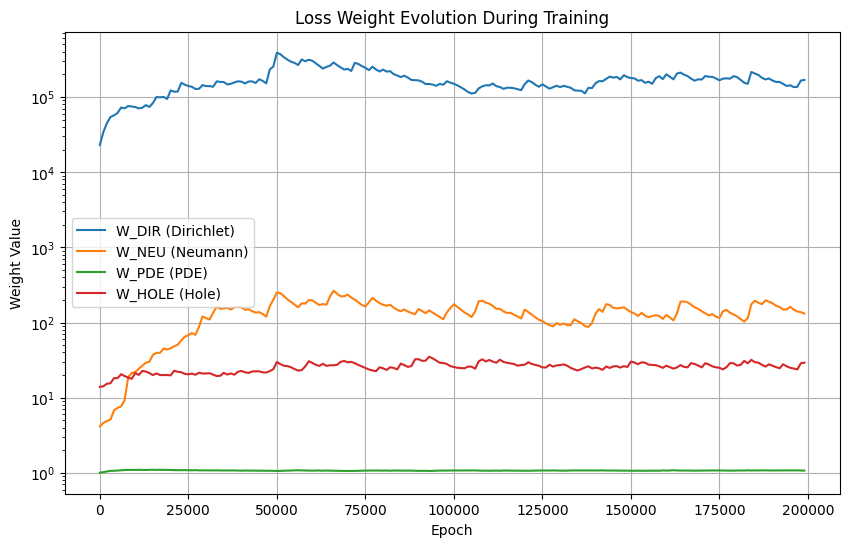

In [39]:
# After training, plot the weight evolution
plt.figure(figsize=(10, 6))

# Convert tensors to numpy arrays before plotting
epochs = [e for e in weight_history['epoch']]  
w_dir = [w.cpu().item() if torch.is_tensor(w) else w for w in weight_history['W_DIR']]
w_neu = [w.cpu().item() if torch.is_tensor(w) else w for w in weight_history['W_NEU']]
w_pde = [w.cpu().item() if torch.is_tensor(w) else w for w in weight_history['W_PDE']]
w_hole = [w.cpu().item() if torch.is_tensor(w) else w for w in weight_history['W_HOLE']]

plt.plot(epochs, w_dir, label='W_DIR (Dirichlet)')
plt.plot(epochs, w_neu, label='W_NEU (Neumann)')
plt.plot(epochs, w_pde, label='W_PDE (PDE)')
plt.plot(epochs, w_hole, label='W_HOLE (Hole)')

plt.xlabel('Epoch')
plt.ylabel('Weight Value')
plt.title(f"Loss Weight Evolution During Training")
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.show()

In [40]:
# Load reference data
csv_data = np.loadtxt(file_path, delimiter=',', skiprows=1)
csv_x = csv_data[:, 0]
csv_y = csv_data[:, 1]
csv_val = np.vstack([csv_x, csv_y]).T
csv_sx = csv_data[:, 2]
csv_sy = csv_data[:, 3]
csv_sxy = csv_data[:, 4]
csv_disp_x = csv_data[:, 8]
csv_disp_y = csv_data[:, 9]
csv_piola1_x = csv_data[:, 10]
csv_piola1_y = csv_data[:, 11]
csv_piola1_xy = csv_data[:, 12]
csv_piola2_x = csv_data[:, 13]
csv_piola2_y = csv_data[:, 14]
csv_piola2_xy = csv_data[:, 15]

# Use CSV data as validation domain
csv_val = torch.tensor(np.vstack([csv_x, csv_y]).T, dtype=DTYPE, device=device, requires_grad=True)

# Compute model predictions on the validation domain (CSV points)
disp = net(csv_val)
def_val = csv_val  + disp
stress = torch.vmap(sigma)(csv_val)
stressP = torch.vmap(first_piola_kirchhoff_stress)(csv_val)
stressS = torch.vmap(second_piola_kirchhoff_stress)(csv_val)

@torch.no_grad()
def make_plot(x, y, variable, title, cmap=sequential.Viridis, size=18.0):
    fig = go.Figure()

    # Convert boundary tensors to numpy if needed
    top_np = top.cpu().numpy() if isinstance(top, torch.Tensor) else top
    bottom_np = bottom.cpu().numpy() if isinstance(bottom, torch.Tensor) else bottom
    left_np = left.cpu().numpy() if isinstance(left, torch.Tensor) else left
    right_np = right.cpu().numpy() if isinstance(right, torch.Tensor) else right

    # Plot boundaries
    m = dict(color="black")
    fig.add_trace(go.Scatter(
        x=top_np[:, 0], y=top_np[:, 1],
        mode="lines",
        marker=m,
        hoverinfo='none'
    ))
    fig.add_trace(go.Scatter(
        x=bottom_np[:, 0], y=bottom_np[:, 1],
        mode="lines",
        marker=m,
        hoverinfo='none'
    ))
    fig.add_trace(go.Scatter(
        x=left_np[:, 0], y=left_np[:, 1],
        mode="lines",
        marker=m,
        hoverinfo='none'
    ))
    fig.add_trace(go.Scatter(
        x=right_np[:, 0], y=right_np[:, 1],
        mode="lines",
        marker=m,
        hoverinfo='none'
    ))

    # Convert all inputs to numpy arrays
    if isinstance(x, torch.Tensor):
        x = x.cpu().numpy()
    if isinstance(y, torch.Tensor):
        y = y.cpu().numpy()
    if isinstance(variable, torch.Tensor):
        variable = variable.detach().cpu().numpy()

    # Plot variable values with custom hover text
    m = dict(
        color=variable,
        colorscale=cmap,
        size=size,
        colorbar=dict(thickness=25)
    )

    # Create custom hover text
    hover_text = [f"x: {xi:.4f}<br>y: {yi:.4f}<br>Value: {val:.4f}"
                 for xi, yi, val in zip(x, y, variable)]

    fig.add_trace(go.Scatter(
        x=x,
        y=y,
        marker=m,
        mode="markers",
        hovertext=hover_text,
        hoverinfo="text"
    ))

    # Plot settings
    fig.layout.yaxis.scaleanchor = "x"
    fig.update_layout(
        template="none",
        width=1200,
        height=1200,
        title=title,
        showlegend=False,
        hovermode='closest'
    )
    fig.update_xaxes(visible=False)
    fig.update_yaxes(visible=False)
    fig.show()

# Plot stresses
make_plot(csv_x, csv_y, stress[:, 0, 0], f"Model Stress in x₁ (Epoch {epoch+1})", cmap=sequential.Inferno)
make_plot(csv_x, csv_y, csv_sx, "CSV Stress in x₁", cmap=sequential.Inferno)

make_plot(csv_x, csv_y, stress[:, 1, 1], f"Model Stress in x₂ (Epoch {epoch+1})", cmap=sequential.Inferno)
make_plot(csv_x, csv_y, csv_sy, "CSV Stress in x₂", cmap=sequential.Inferno)

make_plot(csv_x, csv_y, stress[:, 0, 1], f"Model Stress in x₁x₂ (Epoch {epoch+1})", cmap=sequential.Inferno)
make_plot(csv_x, csv_y, csv_sxy, "CSV Stress in x₁x₂", cmap=sequential.Inferno)

# Plot displacements
make_plot(*def_val.T, disp[:, 0], f"Model Displacement in x₁ (Epoch {epoch+1})", cmap=sequential.Inferno)
make_plot(csv_x, csv_y, csv_disp_x, "CSV Displacement in x₁", cmap=sequential.Inferno)

make_plot(*def_val.T, disp[:, 1], f"Model Displacement in x₂ (Epoch {epoch+1})", cmap=sequential.Inferno)
make_plot(csv_x, csv_y, csv_disp_y, "CSV Displacement in x₂", cmap=sequential.Inferno)

# Plot Piola-Kirchhoff stresses
make_plot(csv_x, csv_y, stressP[:, 0, 0], f"Model First Piola Stress in x₁ (Epoch {epoch+1})", cmap=sequential.Inferno)
make_plot(csv_x, csv_y, csv_piola1_x, "CSV First Piola Stress in x₁", cmap=sequential.Inferno)
make_plot(csv_x, csv_y, stressP[:, 1, 1], f"Model First Piola Stress in x₂ (Epoch {epoch+1})", cmap=sequential.Inferno)
make_plot(csv_x, csv_y, csv_piola1_y, "CSV First Piola Stress in x₂", cmap=sequential.Inferno)
make_plot(csv_x, csv_y, stressP[:, 0, 1], f"Model First Piola Stress in x₁x₂ (Epoch {epoch+1})", cmap=sequential.Inferno)
make_plot(csv_x, csv_y, csv_piola1_xy, "CSV First Piola Stress in x₁x₂", cmap=sequential.Inferno)

In [41]:
@torch.no_grad()
def make_error_plot(x, y, error, title, cmap=sequential.RdBu, size=18.0):
    fig = go.Figure()

    # Convert boundary tensors to numpy if needed
    top_np = top.cpu().numpy() if isinstance(top, torch.Tensor) else top
    bottom_np = bottom.cpu().numpy() if isinstance(bottom, torch.Tensor) else bottom
    left_np = left.cpu().numpy() if isinstance(left, torch.Tensor) else left
    right_np = right.cpu().numpy() if isinstance(right, torch.Tensor) else right

    # Plot domain boundaries
    m = dict(color="black")
    fig.add_trace(go.Scatter(x=top_np[:, 0], y=top_np[:, 1], mode="lines", marker=m, hoverinfo='none'))
    fig.add_trace(go.Scatter(x=bottom_np[:, 0], y=bottom_np[:, 1], mode="lines", marker=m, hoverinfo='none'))
    fig.add_trace(go.Scatter(x=left_np[:, 0], y=left_np[:, 1], mode="lines", marker=m, hoverinfo='none'))
    fig.add_trace(go.Scatter(x=right_np[:, 0], y=right_np[:, 1], mode="lines", marker=m, hoverinfo='none'))

    # Convert tensors to numpy if needed
    x_np = x.cpu().numpy() if isinstance(x, torch.Tensor) else x
    y_np = y.cpu().numpy() if isinstance(y, torch.Tensor) else y
    error_np = np.abs(error.detach().cpu().numpy()) if isinstance(error, torch.Tensor) else np.abs(error)

    # Create hover text
    hover_text = [
        f"x: {xi:.4f}<br>y: {yi:.4f}<br>Absolute Error: {err:.4f}"
        for xi, yi, err in zip(x_np, y_np, error_np)
    ]

    # Plot settings
    max_val = np.max(error_np)
    fig.add_trace(go.Scatter(
        x=x_np,
        y=y_np,
        mode="markers",
        marker=dict(
            color=error_np,
            colorscale=cmap,
            size=size,
            colorbar=dict(thickness=25, title="Absolute Error"),
            cmin=0,
            cmax=max_val
        ),
        hovertext=hover_text,
        hoverinfo="text"
    ))

    # Figure layout
    fig.update_layout(
        template="none",
        width=1200,
        height=1200,
        title=f"Absolute {title}",
        showlegend=False,
        hovermode='closest',
        yaxis_scaleanchor="x"
    )
    fig.update_xaxes(visible=False)
    fig.update_yaxes(visible=False)
    fig.show()

@torch.no_grad()
def make_normalized_error_plot(x, y, error, title, force_value, cmap=sequential.RdBu, size=18.0):
    fig = go.Figure()

    # Convert boundary tensors to numpy if needed
    top_np = top.cpu().numpy() if isinstance(top, torch.Tensor) else top
    bottom_np = bottom.cpu().numpy() if isinstance(bottom, torch.Tensor) else bottom
    left_np = left.cpu().numpy() if isinstance(left, torch.Tensor) else left
    right_np = right.cpu().numpy() if isinstance(right, torch.Tensor) else right

    # Plot domain boundaries
    m = dict(color="black")
    fig.add_trace(go.Scatter(x=top_np[:, 0], y=top_np[:, 1], mode="lines", marker=m, hoverinfo='none'))
    fig.add_trace(go.Scatter(x=bottom_np[:, 0], y=bottom_np[:, 1], mode="lines", marker=m, hoverinfo='none'))
    fig.add_trace(go.Scatter(x=left_np[:, 0], y=left_np[:, 1], mode="lines", marker=m, hoverinfo='none'))
    fig.add_trace(go.Scatter(x=right_np[:, 0], y=right_np[:, 1], mode="lines", marker=m, hoverinfo='none'))

    # Convert tensors to numpy if needed
    x_np = x.cpu().numpy() if isinstance(x, torch.Tensor) else x
    y_np = y.cpu().numpy() if isinstance(y, torch.Tensor) else y
    error_np = np.abs(error.detach().cpu().numpy()) if isinstance(error, torch.Tensor) else np.abs(error)
    norm_errors = error_np / abs(force_value) if force_value != 0 else error_np

    # Create hover text
    hover_text = [
        f"x: {xi:.4f}<br>y: {yi:.4f}<br>Abs. Norm. Error: {norm:.4f}"
        for xi, yi, norm in zip(x_np, y_np, norm_errors)
    ]

    # Plot settings
    max_val = np.max(norm_errors)
    fig.add_trace(go.Scatter(
        x=x_np,
        y=y_np,
        mode="markers",
        marker=dict(
            color=norm_errors,
            colorscale=cmap,
            size=size,
            colorbar=dict(thickness=25, title="Absolute Error"),
            cmin=0,
            cmax=max_val
        ),
        hovertext=hover_text,
        hoverinfo="text"
    ))

    # Figure layout
    fig.update_layout(
        template="none",
        width=1200,
        height=1200,
        title=f"Absolute {title} (Normalized)",
        showlegend=False,
        hovermode='closest',
        yaxis_scaleanchor="x"
    )
    fig.update_xaxes(visible=False)
    fig.update_yaxes(visible=False)
    fig.show()

# Calculate absolute errors
displacement_error_x = torch.abs(pred_displacements[:, 0] - ref_displacements[:, 0])
displacement_error_y = torch.abs(pred_displacements[:, 1] - ref_displacements[:, 1])

# Calculate normalized absolute displacement errors
disp_error_x_norm = displacement_error_x / abs(N1) if N1 != 0 else displacement_error_x
disp_error_y_norm = displacement_error_y / abs(N2) if N2 != 0 else displacement_error_y

# Reference point coordinates
x = ref_points[:, 0]
y = ref_points[:, 1]

# Compute absolute stress errors
stress_ref_points = torch.vmap(sigma)(ref_points)
stress_error_sx = torch.abs(ref_stresses[:, 0] - stress_ref_points[:, 0, 0])
stress_error_sy = torch.abs(ref_stresses[:, 1] - stress_ref_points[:, 1, 1])
stress_error_sxy = torch.abs(ref_stresses[:, 2] - stress_ref_points[:, 0, 1])

# Compute normalized absolute stress errors
stress_error_sx_norm = stress_error_sx / abs(N1) if N1 != 0 else stress_error_sx
stress_error_sy_norm = stress_error_sy / abs(N2) if N2 != 0 else stress_error_sy
stress_error_sxy_norm = stress_error_sxy / (abs(N1+N2)/2) if (N1+N2) != 0 else stress_error_sxy

# Plot absolute displacement errors
make_error_plot(x, y, displacement_error_x, "x₁-Displacement Error")
make_error_plot(x, y, displacement_error_y, "x₂-Displacement Error")


'''
# Plot normalized absolute displacement errors
make_normalized_error_plot(x, y, displacement_error_x, "X-Displacement Error", N1)
make_normalized_error_plot(x, y, displacement_error_y, "Y-Displacement Error", N2)
'''

# Plot absolute stress errors
make_error_plot(x, y, stress_error_sx, "x₁-Stress Error")
make_error_plot(x, y, stress_error_sy, "x₂-Stress Error")
make_error_plot(x, y, stress_error_sxy, "Shear Stress Error")

'''
# Plot normalized absolute stress errors
make_normalized_error_plot(x, y, stress_error_sx, "X-Stress Error", N1)
make_normalized_error_plot(x, y, stress_error_sy, "Y-Stress Error", N2)
make_normalized_error_plot(x, y, stress_error_sxy, "Shear Stress Error", (N1+N2)/2)
'''

'\n# Plot normalized absolute stress errors\nmake_normalized_error_plot(x, y, stress_error_sx, "X-Stress Error", N1)\nmake_normalized_error_plot(x, y, stress_error_sy, "Y-Stress Error", N2)\nmake_normalized_error_plot(x, y, stress_error_sxy, "Shear Stress Error", (N1+N2)/2)\n'

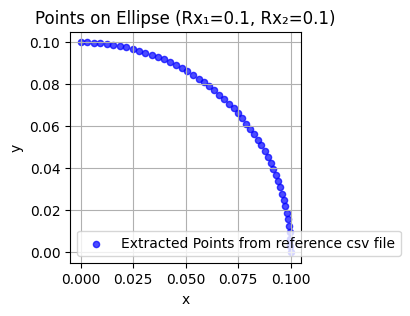

In [42]:
# Plotting - Boundary Points Visualization
points, stresspoints = extract_ellipse_boundary_data(file_path, tol=0.05)

# Convert to numpy if they're tensors (with gradient detachment)
if isinstance(points, torch.Tensor):
    points = points.detach().cpu().numpy()
if isinstance(stresspoints, torch.Tensor):
    stresspoints = stresspoints.detach().cpu().numpy()

plt.figure(figsize=(4, 3))
plt.scatter(points[:, 0], points[:, 1], s=20, color='blue', alpha=0.7, 
           label='Extracted Points from reference csv file')
plt.gca().set_aspect('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Points on Ellipse (Rx₁={Rx:.1f}, Rx₂={Ry:.1f})')
plt.legend()
plt.grid(True)

# Stress Comparison Plot
points_hole, hole_stress = extract_ellipse_boundary_data(file_path, tol=0.05)

# Convert to numpy if they're tensors (with gradient detachment)
if isinstance(points_hole, torch.Tensor):
    points_hole = points_hole.detach().cpu().numpy()
if isinstance(hole_stress, torch.Tensor):
    hole_stress = hole_stress.detach().cpu().numpy()

points_hole_tensor = torch.tensor(points_hole, device=device, dtype=torch.float32)

# Compute stresses and detach before converting to numpy
with torch.no_grad():
    stress_hole = torch.vmap(sigma)(points_hole_tensor).cpu().numpy()

# Sort by x-coordinate
sort_idx = np.argsort(points_hole[:, 0])
points_hole_sorted = points_hole[sort_idx]
hole_stress_sorted = hole_stress[sort_idx]

# Create figure
fig = go.Figure()

# Define consistent line and marker styles
line_width = 3
marker_size = 8

# σ_xx components
fig.add_trace(
    go.Scatter(
        x=points_hole[:, 0],
        y=stress_hole[:, 0, 0],
        marker=dict(color="blue", size=marker_size),
        mode="markers",
        name="σ_11 (PINN)",
    )
)
fig.add_trace(
    go.Scatter(
        x=points_hole_sorted[:, 0],
        y=hole_stress_sorted[:, 0],
        line=dict(color="blue", width=line_width),
        mode="lines",
        name="σ_11 (FEM)",
    )
)

# σ_yy components
fig.add_trace(
    go.Scatter(
        x=points_hole[:, 0],
        y=stress_hole[:, 1, 1],
        marker=dict(color="orange", size=marker_size),
        mode="markers",
        name="σ_22 (PINN)",
    )
)
fig.add_trace(
    go.Scatter(
        x=points_hole_sorted[:, 0],
        y=hole_stress_sorted[:, 1],
        line=dict(color="orange", width=line_width),
        mode="lines",
        name="σ_22 (FEM)",
    )
)

# σ_xy components
fig.add_trace(
    go.Scatter(
        x=points_hole[:, 0],
        y=stress_hole[:, 0, 1],
        marker=dict(color="green", size=marker_size),
        mode="markers",
        name="σ_12 (PINN)",
    )
)
fig.add_trace(
    go.Scatter(
        x=points_hole_sorted[:, 0],
        y=hole_stress_sorted[:, 2],
        line=dict(color="green", width=line_width),
        mode="lines",
        name="σ_12 (FEM)",
    )
)

# Layout configuration with improved legend placement
fig.update_layout(
    template="plotly_white",
    width=1600,
    height=1000,
    title={
        'text': "Stress Components at Hole Boundary",
        'y':0.9,
        'x':0.5,
        'xanchor': 'center',
        'yanchor': 'top',
        'font': dict(size=30)  # Large title size
    },
    xaxis=dict(
        title=dict(
            text="x₁-coordinate",
            font=dict(size=28)  # Large x-axis title
        ),
        tickfont=dict(size=24)  # Large x-axis numbers
    ),
    yaxis=dict(
        title=dict(
            text="Stress Value", 
            font=dict(size=28)  # Large y-axis title
        ),
        tickfont=dict(size=24)  # Large y-axis numbers
    ),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.05,
        xanchor="center",
        x=0.5,
        itemwidth=80,
        font=dict(size=20)  # Legend font size
    ),
    margin=dict(
        l=50,
        r=50,
        b=50,
        t=100,
        pad=4
    ),
    hovermode="x unified"
)

fig.show()